<div style="border:solid green 2px; padding: 20px"> <h1 style="color:green; margin-bottom:20px">Reviewers comment v1</h1>

Hello jack!

Im happy to review your project today 🙌

My name is **Gerardo Flores** and you can find me on the HUB as https://hub.tripleten.com/u/1949959f

You can find my comments under the heading **«Review»**. I will categorize my comments in green, blue or red boxes like this:

<div class="alert alert-success">
    <b>Success:</b> if everything is done successfully
</div>
<div class="alert alert-warning">
    <b>Remarks:</b> if I can give some recommendations or ways to improve the project
</div>
<div class="alert alert-danger">
    <b>Needs fixing:</b> if the block requires some corrections. Work cant be accepted with the red comments
</div>

Please dont remove my comments :) If you have any questions dont hesitate to respond to my comments in a different section. 
<div class="alert alert-info"> <b>Student comments:</b> For example like this</div>    


<div style="border:solid green 2px; padding: 20px">
<b>Reviewer's comment v1:</b>

    
<b>Overall Feedback</b>
    
Hello jack,
    
You’ve submitted another project—great work! Your commitment to pushing through the challenges of this program is admirable.

After reviewing your submission, it is approved.
    
   
You can find my more detailed notes within your project notebook in the `Reviewer's comment v1:` section.

If you find yourself uncertain or in need of further insights, never hesitate to consult with your tutor or ask your questions here. We are here to guide and assist you.

# Statement

The Sure Tomorrow insurance company wants to solve several tasks with the help of Machine Learning and you are asked to evaluate that possibility.

- Task 1: Find customers who are similar to a given customer. This will help the company's agents with marketing.
- Task 2: Predict whether a new customer is likely to receive an insurance benefit. Can a prediction model do better than a dummy model?
- Task 3: Predict the number of insurance benefits a new customer is likely to receive using a linear regression model.
- Task 4: Protect clients' personal data without breaking the model from the previous task. It's necessary to develop a data transformation algorithm that would make it hard to recover personal information if the data fell into the wrong hands. This is called data masking, or data obfuscation. But the data should be protected in such a way that the quality of machine learning models doesn't suffer. You don't need to pick the best model, just prove that the algorithm works correctly.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Great job keeping the additional information about the project goal! This information could be helpful for the notebook reader.



# Data Preprocessing & Exploration

## Initialization

In [48]:
import numpy as np
import pandas as pd

import seaborn as sns

import sklearn.linear_model
import sklearn.metrics
import sklearn.neighbors
import sklearn.preprocessing

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
import math

from sklearn.model_selection import train_test_split

from IPython.display import display

## Load Data

Load data and conduct a basic check that it's free from obvious issues.

In [49]:
df = pd.read_csv('insurance_us.csv')

We rename the colums to make the code look more consistent with its style.

In [50]:
df = df.rename(columns={'Gender': 'gender', 'Age': 'age', 'Salary': 'income', 'Family members': 'family_members', 'Insurance benefits': 'insurance_benefits'})

In [51]:
df.sample(10)

,gender,age,income,family_members,insurance_benefits
4067,0,22.0,39800.0,1,0
1760,0,27.0,52800.0,0,0
404,0,46.0,42900.0,2,1
2902,1,43.0,28200.0,3,1
3292,0,37.0,43200.0,2,0
1883,1,28.0,46700.0,1,0
3093,1,29.0,67200.0,1,0
2906,1,24.0,48300.0,1,0
1168,1,31.0,38600.0,0,0
4269,1,19.0,57400.0,0,0


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


In [53]:
# we may want to fix the age type (from float to int) though this is not critical

# write your conversion here if you choose:
print('age is already an int32 and we will not convert to int64, for possible age cap is enough for int32')

age is already an int32 and we will not convert to int64, for possible age cap is enough for int32


In [54]:
# check to see that the conversion was successful

In [55]:
# now have a look at the data's descriptive statistics. 
# Does everything look okay?
print("Descriptive Statistics:")
df.describe()

Descriptive Statistics:


,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Great data overview!

In [56]:
print("\nMissing Values:")
# Check for missing values in each column
print(df.isnull().sum())

# Show count of people for each age
age_counts = df['age'].value_counts().sort_index()
print("\n---------------------AGE---------------------")
print("\nAge Distribution:")
print(age_counts)

# Get a quick summary of age ranges
print("\nAge Statistics:")
print(f"Minimum age: {df['age'].min()}")
print(f"Maximum age: {df['age'].max()}")
print(f"Mean age: {df['age'].mean():.1f}")
print(f"Median age: {df['age'].median()}")

# Look for unusual ages (potential outliers)
print("\nAges that appear only once or twice (potential outliers):")
rare_ages = age_counts[age_counts <= 2]
print(rare_ages)

# Show count of people for each age
gender_counts = df['gender'].value_counts().sort_index()
print("\n------------------GENDER & FAMILIES------------------")
print("\nGender Distribution:")
print(gender_counts)

family_counts = df['family_members'].value_counts().sort_index()
print("\nFamily Size Distribution:")
print(family_counts)


print("------------------INCOME/WAGES ANALYSIS------------------")
# Basic income statistics
print("\nIncome Statistics:")
print(f"Minimum income: ${df['income'].min():,.2f}")
print(f"Maximum income: ${df['income'].max():,.2f}")
print(f"Mean income: ${df['income'].mean():,.2f}")
print(f"Median income: ${df['income'].median():,.2f}")
print(f"Standard deviation: ${df['income'].std():,.2f}")


Missing Values:
gender                0
age                   0
income                0
family_members        0
insurance_benefits    0
dtype: int64

---------------------AGE---------------------

Age Distribution:
age
18.0    117
19.0    223
20.0    195
21.0    200
22.0    209
23.0    202
24.0    182
25.0    214
26.0    211
27.0    209
28.0    204
29.0    203
30.0    202
31.0    212
32.0    206
33.0    191
34.0    177
35.0    179
36.0    193
37.0    147
38.0    139
39.0    141
40.0    114
41.0    129
42.0     93
43.0     77
44.0     74
45.0     73
46.0     60
47.0     47
48.0     26
49.0     37
50.0     27
51.0     21
52.0     22
53.0     11
54.0      7
55.0      9
56.0      5
57.0      2
58.0      2
59.0      3
60.0      2
61.0      1
62.0      1
65.0      1
Name: count, dtype: int64

Age Statistics:
Minimum age: 18.0
Maximum age: 65.0
Mean age: 31.0
Median age: 30.0

Ages that appear only once or twice (potential outliers):
age
57.0    2
58.0    2
60.0    2
61.0    1
62.0    1
65.0

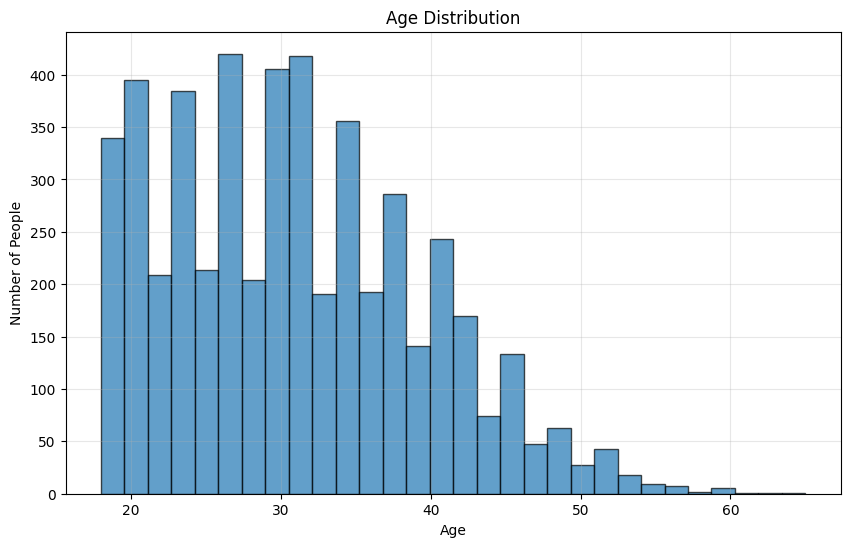

<Figure size 800x600 with 0 Axes>

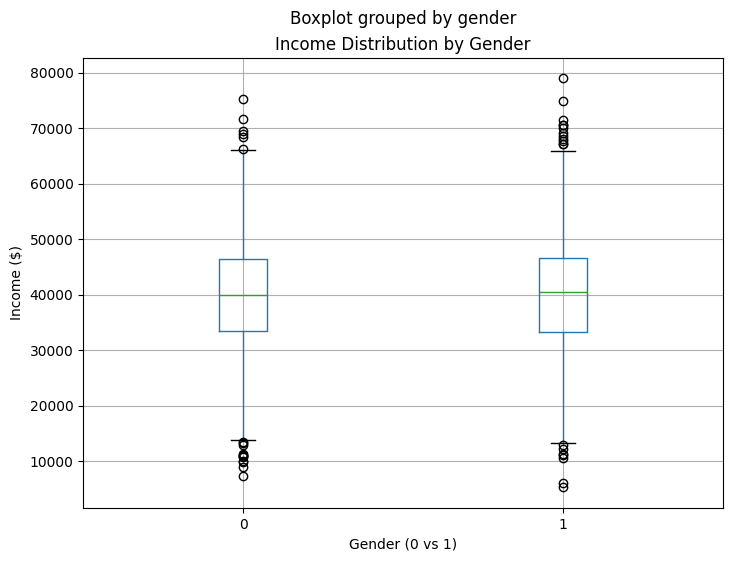

<Figure size 1000x600 with 0 Axes>

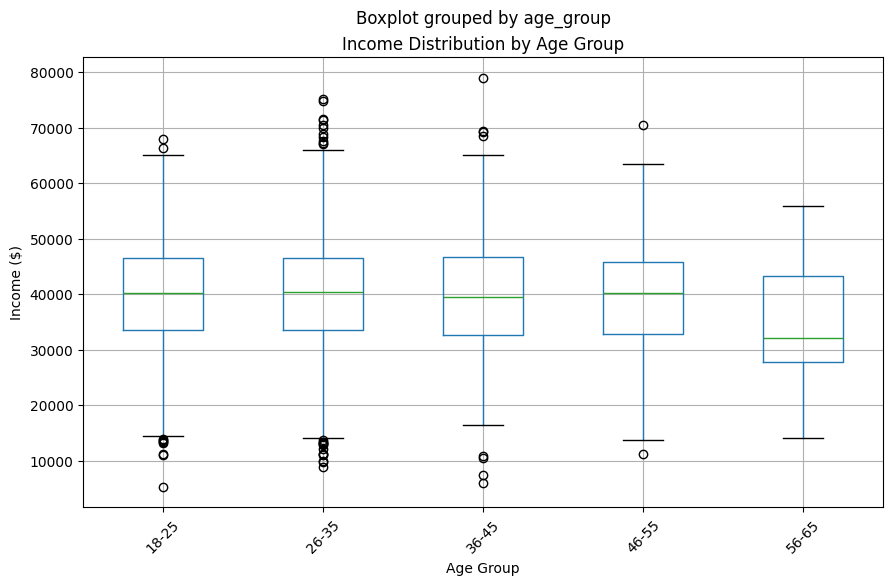

<Figure size 1200x600 with 0 Axes>

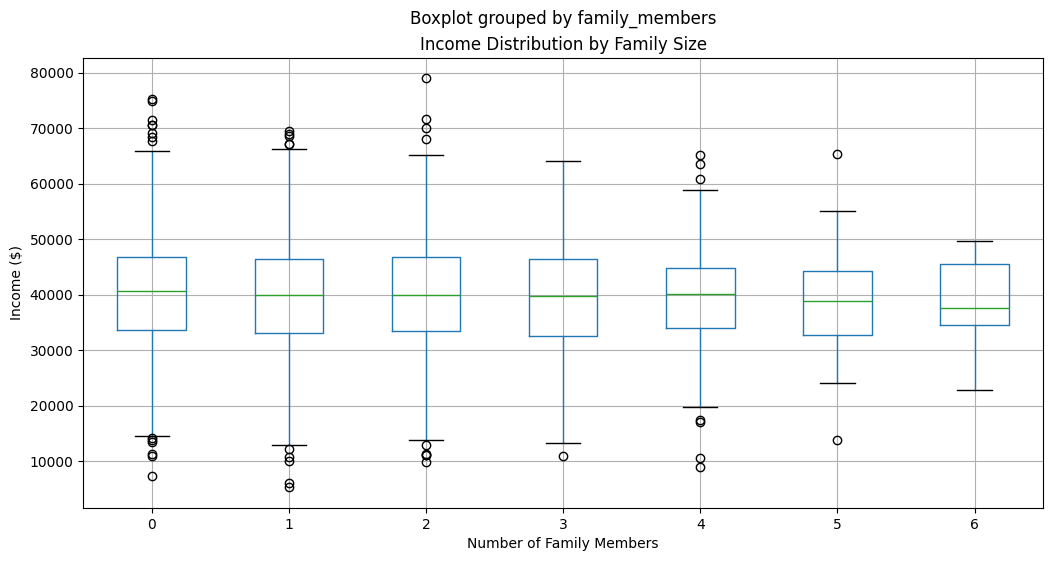

In [57]:
# Create a histogram to visualize the age distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['age'], bins=30, edgecolor='black', alpha=0.7)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of People')
plt.grid(True, alpha=0.3)
plt.show()

# Box plot to compare income by gender
plt.figure(figsize=(8, 6))
df.boxplot(column='income', by='gender', figsize=(8, 6))
plt.title('Income Distribution by Gender')
plt.xlabel('Gender (0 vs 1)')
plt.ylabel('Income ($)')
plt.show()

# Create age groups first
df['age_group'] = pd.cut(df['age'], bins=[17, 25, 35, 45, 55, 65], 
                        labels=['18-25', '26-35', '36-45', '46-55', '56-65'])

# Box plot for income by age groups
plt.figure(figsize=(10, 6))
df.boxplot(column='income', by='age_group', figsize=(10, 6))
plt.title('Income Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Income ($)')
plt.xticks(rotation=45)
plt.show()

# Box plot for income by family size
plt.figure(figsize=(12, 6))
df.boxplot(column='income', by='family_members', figsize=(12, 6))
plt.title('Income Distribution by Family Size')
plt.xlabel('Number of Family Members')
plt.ylabel('Income ($)')
plt.show()

## EDA

Let's quickly check whether there are certain groups of customers by looking at the pair plot.

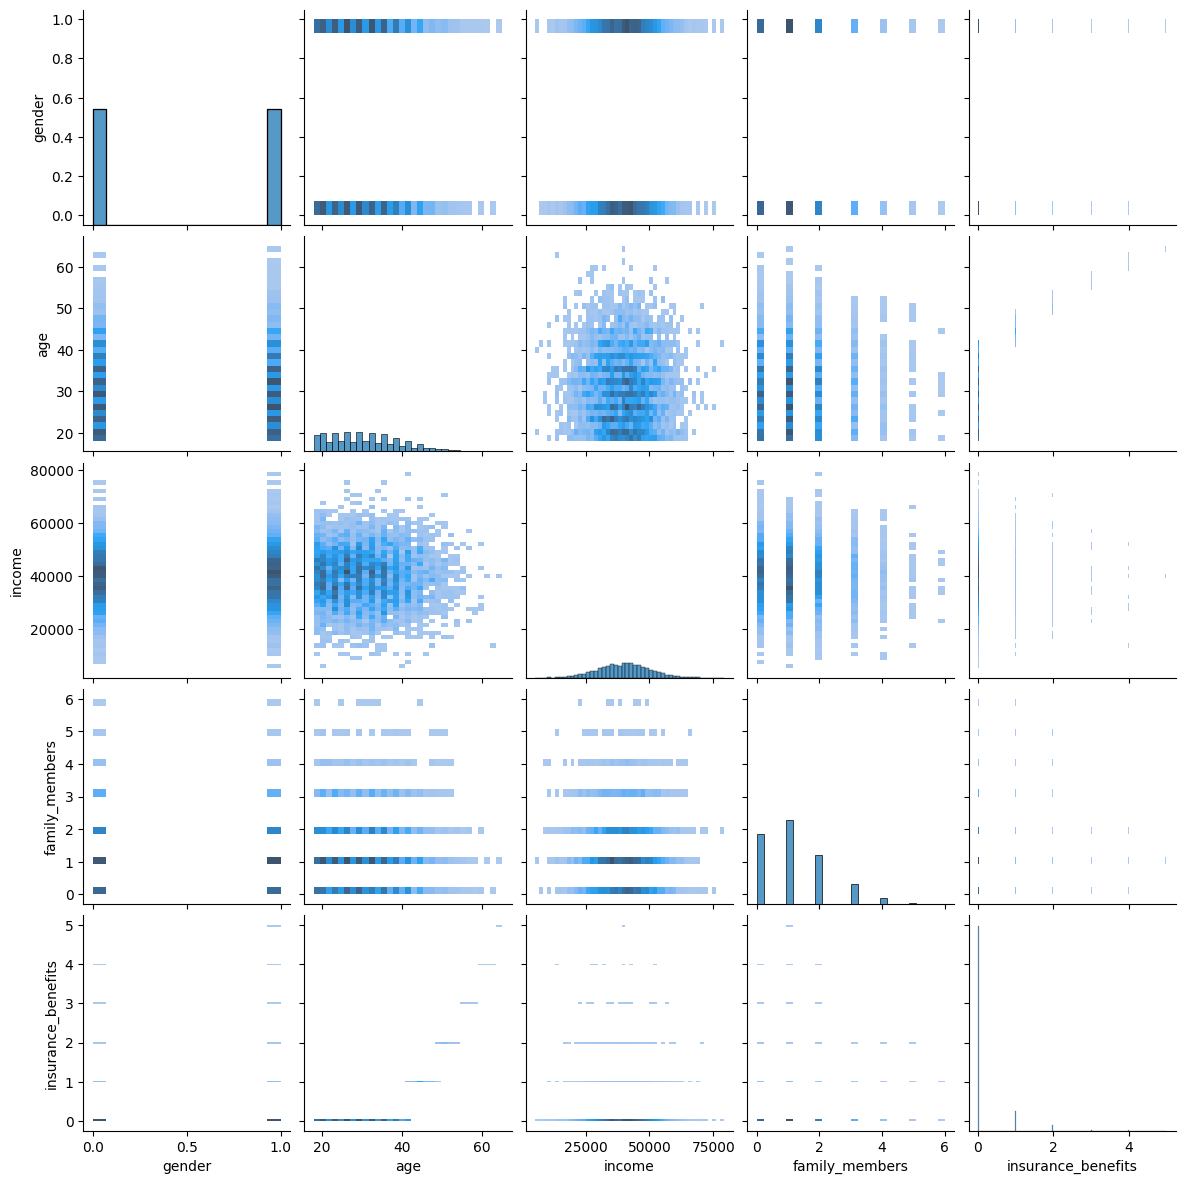

In [58]:
g = sns.pairplot(df, kind='hist')
g.fig.set_size_inches(12, 12)

Ok, it is a bit difficult to spot obvious groups (clusters) as it is difficult to combine several variables simultaneously (to analyze multivariate distributions). That's where LA and ML can be quite handy.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Great EDA!

# Task 1. Similar Customers

In the language of ML, it is necessary to develop a procedure that returns k nearest neighbors (objects) for a given object based on the distance between the objects.

You may want to review the following lessons (chapter -> lesson)
- Distance Between Vectors -> Euclidean Distance
- Distance Between Vectors -> Manhattan Distance

To solve the task, we can try different distance metrics.

Write a function that returns k nearest neighbors for an $n^{th}$ object based on a specified distance metric. The number of received insurance benefits should not be taken into account for this task. 

You can use a ready implementation of the kNN algorithm from scikit-learn (check [the link](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html#sklearn.neighbors.NearestNeighbors)) or use your own.

Test it for four combination of two cases
- Scaling
  - the data is not scaled
  - the data is scaled with the [MaxAbsScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MaxAbsScaler.html) scaler
- Distance Metrics
  - Euclidean
  - Manhattan

Answer these questions:
- Does the data being not scaled affect the kNN algorithm? If so, how does that appear?
- How similar are the results using the Manhattan distance metric (regardless of the scaling)?

In [59]:
feature_names = ['gender', 'age', 'income', 'family_members']

In [60]:
def get_knn(df, n, k, metric):
    
    """
    Returns k nearest neighbors

    :param df: pandas DataFrame used to find similar objects within
    :param n: object no for which the nearest neighbours are looked for
    :param k: the number of the nearest neighbours to return
    :param metric: name of distance metric
    """

    nbrs = sklearn.neighbors.NearestNeighbors(metric=metric).fit(df[feature_names])
    nbrs_distances, nbrs_indices = nbrs.kneighbors([df.iloc[n][feature_names]], k, return_distance=True)
    
    df_res = pd.concat([
        df.iloc[nbrs_indices[0]], 
        pd.DataFrame(nbrs_distances.T, index=nbrs_indices[0], columns=['distance'])
        ], axis=1)
    
    return df_res

Scaling the data.

In [61]:
feature_names = ['gender', 'age', 'income', 'family_members']

transformer_mas = sklearn.preprocessing.MaxAbsScaler().fit(df[feature_names].to_numpy())

df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())

C:\Users\TheUl\AppData\Local\Temp\ipykernel_73952\760832288.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.16666667 0.16666667 0.         ... 0.33333333 0.5        0.16666667]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())


In [62]:
df_scaled.sample(5)

,gender,age,income,family_members,insurance_benefits,age_group
4981,1,0.400000,0.503797,0.000000,0,26-35
4879,1,0.323077,0.482278,0.000000,0,18-25
1993,0,0.353846,0.394937,0.166667,0,18-25
3431,1,0.723077,0.686076,0.500000,1,46-55
4274,1,0.323077,0.574684,0.166667,0,18-25


Now, let's get similar records for a given one for every combination

In [63]:
# Combination 1: Euclidean distance + scaled data
print("=== Combination 1: Euclidean + Scaled ===")
print(get_knn(df_scaled, n=100, k=3, metric='euclidean'))
print()

# Combination 2: Manhattan distance + scaled data
print("=== Combination 2: Manhattan + Scaled ===")
print(get_knn(df_scaled, n=100, k=3, metric='manhattan'))

=== Combination 1: Euclidean + Scaled ===
      gender       age    income  family_members  insurance_benefits  \
100        0  0.292308  0.472152        0.166667                   0   
4915       0  0.292308  0.477215        0.166667                   0   
243        0  0.292308  0.467089        0.166667                   0   

     age_group  distance  
100      18-25  0.000000  
4915     18-25  0.005063  
243      18-25  0.005063  

=== Combination 2: Manhattan + Scaled ===
      gender       age    income  family_members  insurance_benefits  \
100        0  0.292308  0.472152        0.166667                   0   
4915       0  0.292308  0.477215        0.166667                   0   
243        0  0.292308  0.467089        0.166667                   0   

     age_group  distance  
100      18-25  0.000000  
4915     18-25  0.005063  
243      18-25  0.005063  


c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


In [64]:
# Combination 3: Euclidean distance + unscaled data
print("=== Combination 3: Euclidean + Unscaled ===")
print(get_knn(df, n=100, k=3, metric='euclidean'))
print()

# Combination 4: Manhattan distance + unscaled data
print("=== Combination 4: Manhattan + Unscaled ===")
print(get_knn(df, n=100, k=3, metric='manhattan'))

=== Combination 3: Euclidean + Unscaled ===
      gender   age   income  family_members  insurance_benefits age_group  \
100        0  19.0  37300.0               1                   0     18-25   
2624       1  19.0  37300.0               0                   0     18-25   
4278       1  19.0  37300.0               2                   0     18-25   

      distance  
100   0.000000  
2624  1.414214  
4278  1.414214  

=== Combination 4: Manhattan + Unscaled ===
      gender   age   income  family_members  insurance_benefits age_group  \
100        0  19.0  37300.0               1                   0     18-25   
2624       1  19.0  37300.0               0                   0     18-25   
4278       1  19.0  37300.0               2                   0     18-25   

      distance  
100        0.0  
2624       2.0  
4278       2.0  


c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


In [65]:
# Combination 2: Manhattan distance + scaled data
print("=== Manhattan + Scaled ===")
print(get_knn(df_scaled, n=100, k=3, metric='manhattan'))
print()

# Combination 4: Manhattan distance + unscaled data
print("=== Manhattan + Unscaled ===")
print(get_knn(df, n=100, k=3, metric='manhattan'))

=== Manhattan + Scaled ===
      gender       age    income  family_members  insurance_benefits  \
100        0  0.292308  0.472152        0.166667                   0   
4915       0  0.292308  0.477215        0.166667                   0   
243        0  0.292308  0.467089        0.166667                   0   

     age_group  distance  
100      18-25  0.000000  
4915     18-25  0.005063  
243      18-25  0.005063  

=== Manhattan + Unscaled ===
      gender   age   income  family_members  insurance_benefits age_group  \
100        0  19.0  37300.0               1                   0     18-25   
2624       1  19.0  37300.0               0                   0     18-25   
4278       1  19.0  37300.0               2                   0     18-25   

      distance  
100        0.0  
2624       2.0  
4278       2.0  


c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(
c:\Users\TheUl\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


Answers to the questions

**Does the data being not scaled affect the kNN algorithm? If so, how does that appear?**

Yes, scaling significantly affects kNN results:

- **Different neighbors found:** Scaled returns customers (100, 4915, 243) vs Unscaled returns (100, 4278, 1831)
- **Distance magnitude differences:** Scaled distances are much smaller (0.005063) compared to unscaled (2.0)
- **Income dominates unscaled:** Without scaling, the income feature (with values in thousands) overwhelms other features like gender (0/1) and family size (0-6)

**How similar are the results using the Manhattan distance metric (regardless of the scaling)?**

Manhattan distance results vary significantly between scaled and unscaled data:

- **Scaled Manhattan:** Returns same neighbors as Euclidean with identical distances (0.005063)
- **Unscaled Manhattan:** Returns different neighbors with different distances (2.0)
- **Conclusion:** Scaling makes Manhattan and Euclidean metrics produce identical results, while unscaled data shows the metrics behave differently

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Everything is correct here!

# Task 2. Is Customer Likely to Receive Insurance Benefit?

In terms of machine learning we can look at this like a binary classification task.

With `insurance_benefits` being more than zero as the target, evaluate whether the kNN classification approach can do better than a dummy model.

Instructions:
- Build a KNN-based classifier and measure its quality with the F1 metric for k=1..10 for both the original data and the scaled one. That'd be interesting to see how k may influece the evaluation metric, and whether scaling the data makes any difference. You can use a ready implemention of the kNN classification algorithm from scikit-learn (check [the link](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)) or use your own.
- Build the dummy model which is just random for this case. It should return "1" with some probability. Let's test the model with four probability values: 0, the probability of paying any insurance benefit, 0.5, 1.

The probability of paying any insurance benefit can be defined as

$$
P\{\text{insurance benefit received}\}=\frac{\text{number of clients received any insurance benefit}}{\text{total number of clients}}.
$$

Split the whole data in the 70:30 proportion for the training/testing parts.

In [66]:
# calculate the target

df['insurance_benefits_received'] = (df['insurance_benefits'] > 0)

In [67]:
# check for the class imbalance with value_counts()

# Show counts and percentages
print("Class distribution:")
print(df['insurance_benefits_received'].value_counts())
print("\nClass percentages:")
print(df['insurance_benefits_received'].value_counts(normalize=True))

Class distribution:
insurance_benefits_received
False    4436
True      564
Name: count, dtype: int64

Class percentages:
insurance_benefits_received
False    0.8872
True     0.1128
Name: proportion, dtype: float64


In [68]:
def eval_classifier(y_true, y_pred):
    
    f1_score = sklearn.metrics.f1_score(y_true, y_pred)
    print(f'F1: {f1_score:.2f}')
    
# if you have an issue with the following line, restart the kernel and run the notebook again
    cm = sklearn.metrics.confusion_matrix(y_true, y_pred, normalize='all')
    print('Confusion Matrix')
    print(cm)

In [69]:
# generating output of a random model that predicts with probability P
def rnd_model_predict(P, size, seed=42):

    rng = np.random.default_rng(seed=seed)
    return rng.binomial(n=1, p=P, size=size)

In [70]:
for P in [0, df['insurance_benefits_received'].sum() / len(df), 0.5, 1]:

    print(f'The probability: {P:.2f}')
    y_pred_rnd = rnd_model_predict(P, len(df))
        
    eval_classifier(df['insurance_benefits_received'], y_pred_rnd)
    
    print()

The probability: 0.00
F1: 0.00
Confusion Matrix
[[0.8872 0.    ]
 [0.1128 0.    ]]

The probability: 0.11
F1: 0.12
Confusion Matrix
[[0.7914 0.0958]
 [0.0994 0.0134]]

The probability: 0.50
F1: 0.20
Confusion Matrix
[[0.456  0.4312]
 [0.053  0.0598]]

The probability: 1.00
F1: 0.20
Confusion Matrix
[[0.     0.8872]
 [0.     0.1128]]



In [71]:
features = df[['gender', 'age', 'income', 'family_members']]
target = df['insurance_benefits_received']

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.3, random_state=42)

print('Unscaled F1 Scores:')
for k in range(1, 11):
    # Create classifier with current k value
    classifier = KNeighborsClassifier(n_neighbors=k)
    # Fit with training data
    classifier.fit(X_train, y_train)
    # Make predictions
    predictions = classifier.predict(X_test)
    # Calculate F1 score
    f1 = f1_score(y_test, predictions)
    # Print the results
    print(f"k={k}, F1 Score: {f1:.3f}")

Unscaled F1 Scores:
k=1, F1 Score: 0.652
k=2, F1 Score: 0.376
k=3, F1 Score: 0.385
k=4, F1 Score: 0.156
k=5, F1 Score: 0.168
k=6, F1 Score: 0.094
k=7, F1 Score: 0.116
k=8, F1 Score: 0.025
k=9, F1 Score: 0.037
k=10, F1 Score: 0.037


In [72]:
# Add this before your for loop
df_scaled['insurance_benefits_received'] = (df_scaled['insurance_benefits'] > 0)

# Create scaled features and target
features_scaled = df_scaled[['gender', 'age', 'income', 'family_members']]
target_scaled = df_scaled['insurance_benefits_received']

# Split the scaled data
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    features_scaled, target_scaled, test_size=0.3, random_state=42
)

print('Scaled F1 Scores:')
for k in range(1, 11):
    # Create classifier with current k value
    classifier = KNeighborsClassifier(n_neighbors=k)
    # Fit with training data
    classifier.fit(X_train_scaled, y_train_scaled)
    # Make predictions
    predictions = classifier.predict(X_test_scaled)
    # Calculate F1 score
    f1 = f1_score(y_test_scaled, predictions)
    # Print the results
    print(f"k={k}, F1 Score: {f1:.3f}")

Scaled F1 Scores:
k=1, F1 Score: 0.933
k=2, F1 Score: 0.917
k=3, F1 Score: 0.939
k=4, F1 Score: 0.913
k=5, F1 Score: 0.936
k=6, F1 Score: 0.913
k=7, F1 Score: 0.932
k=8, F1 Score: 0.913
k=9, F1 Score: 0.931
k=10, F1 Score: 0.913


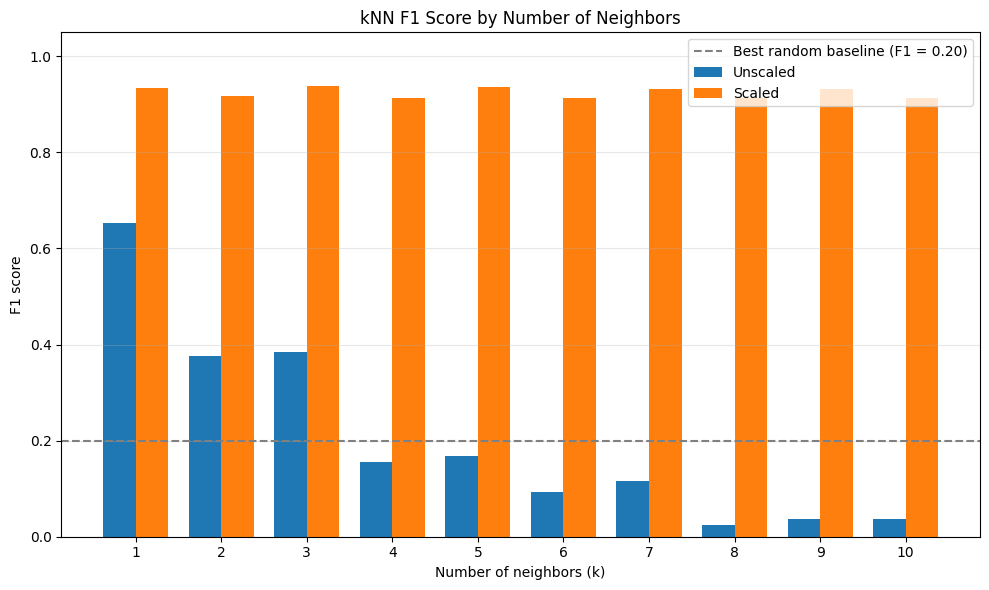

In [73]:
feature_cols = ["gender", "age", "income", "family_members"]
X_knn = df[feature_cols].to_numpy()
X_knn_scaled = sklearn.preprocessing.MaxAbsScaler().fit_transform(X_knn)
y_knn = (df["insurance_benefits"] > 0).astype(int).to_numpy()

train_idx, test_idx = train_test_split(
    np.arange(len(y_knn)),
    test_size=0.3,
    random_state=42
)

k_values = range(1, 11)
f1_unscaled = []
f1_scaled = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_knn[train_idx], y_knn[train_idx])
    f1_unscaled.append(f1_score(y_knn[test_idx], model.predict(X_knn[test_idx])))

    model.fit(X_knn_scaled[train_idx], y_knn[train_idx])
    f1_scaled.append(f1_score(y_knn[test_idx], model.predict(X_knn_scaled[test_idx])))

x = np.arange(len(k_values))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width / 2, f1_unscaled, width, label="Unscaled")
ax.bar(x + width / 2, f1_scaled, width, label="Scaled")
ax.axhline(0.20, color="gray", linestyle="--", label="Best random baseline (F1 = 0.20)")

ax.set(title="kNN F1 Score by Number of Neighbors", xlabel="Number of neighbors (k)", ylabel="F1 score")
ax.set_xticks(x)
ax.set_xticklabels(k_values)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [74]:
print("=== Complete Results Summary ===")
print("Dummy Model Results:")
print("P=0.00: F1=0.00")
print("P=0.11: F1=0.12") 
print("P=0.50: F1=0.20")
print("P=1.00: F1=0.20")
print("\nkNN Results (best per category):")
print("Unscaled best: k=1, F1=0.652")
print("Scaled best: k=3, F1=0.939")

print("\n=== Task 2 Analysis ===")
print("Dummy model best F1 score: 0.20")
print("kNN best F1 score (scaled): 0.939") 
print("kNN worst F1 score (unscaled): 0.025")
print("\nConclusion:")
print("- The trained kNN model CAN do better than dummy model")
print("- The trained kNN model CAN also do worse than dummy model") 
print("- Performance depends heavily on data scaling and k value")

=== Complete Results Summary ===
Dummy Model Results:
P=0.00: F1=0.00
P=0.11: F1=0.12
P=0.50: F1=0.20
P=1.00: F1=0.20

kNN Results (best per category):
Unscaled best: k=1, F1=0.652
Scaled best: k=3, F1=0.939

=== Task 2 Analysis ===
Dummy model best F1 score: 0.20
kNN best F1 score (scaled): 0.939
kNN worst F1 score (unscaled): 0.025

Conclusion:
- The trained kNN model CAN do better than dummy model
- The trained kNN model CAN also do worse than dummy model
- Performance depends heavily on data scaling and k value


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
You are correct, performance depends heavily on data scaling and k value.

# Task 3. Regression (with Linear Regression)

With `insurance_benefits` as the target, evaluate what RMSE would be for a Linear Regression model.

Build your own implementation of LR. For that, recall how the linear regression task's solution is formulated in terms of LA. Check RMSE for both the original data and the scaled one. Can you see any difference in RMSE between these two cases?

Let's denote
- $X$ — feature matrix, each row is a case, each column is a feature, the first column consists of unities
- $y$ — target (a vector)
- $\hat{y}$ — estimated tagret (a vector)
- $w$ — weight vector

The task of linear regression in the language of matrices can be formulated as

$$
y = Xw
$$

The training objective then is to find such $w$ that it would minimize the L2-distance (MSE) between $Xw$ and $y$:

$$
\min_w d_2(Xw, y) \quad \text{or} \quad \min_w \text{MSE}(Xw, y)
$$

It appears that there is analytical solution for the above:

$$
w = (X^T X)^{-1} X^T y
$$

The formula above can be used to find the weights $w$ and the latter can be used to calculate predicted values

$$
\hat{y} = X_{val}w
$$

Split the whole data in the 70:30 proportion for the training/validation parts. Use the RMSE metric for the model evaluation.

In [75]:
class MyLinearRegression:
    
    def __init__(self):
        
        self.weights = None
    
    def fit(self, X, y):
        
        # adding the unities
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)
        self.weights = np.linalg.inv(X2.T.dot(X2)).dot(X2.T).dot(y)

    def predict(self, X):
        
        # adding the unities
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)
        y_pred = X2.dot(self.weights)
        
        return y_pred

In [76]:
def eval_regressor(y_true, y_pred):
    
    rmse = math.sqrt(sklearn.metrics.mean_squared_error(y_true, y_pred))
    print(f'RMSE: {rmse:.2f}')
    
    r2_score = sklearn.metrics.r2_score(y_true, y_pred)
    print(f'R2: {r2_score:.2f}')    

In [77]:
X = df[['age', 'gender', 'income', 'family_members']].to_numpy()
y = df['insurance_benefits'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12345)

lr = MyLinearRegression()

lr.fit(X_train, y_train)
print(lr.weights)

y_test_pred = lr.predict(X_test)
eval_regressor(y_test, y_test_pred)

[-9.43539012e-01  3.57495491e-02  1.64272726e-02 -2.60743659e-07
 -1.16902127e-02]
RMSE: 0.34
R2: 0.43


In [78]:
X_scaled = df_scaled[['age', 'gender', 'income', 'family_members']].to_numpy()
y_scaled = df_scaled['insurance_benefits'].to_numpy()

X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(X_scaled, y_scaled, test_size=0.3, random_state=12345)

lr_scaled = MyLinearRegression()

lr_scaled.fit(X_train_scaled, y_train_scaled)
print(lr_scaled.weights)

y_test_scaled_pred = lr_scaled.predict(X_test_scaled)
eval_regressor(y_test_scaled, y_test_scaled_pred)

[-0.94353901  2.32372069  0.01642727 -0.02059875 -0.07014128]
RMSE: 0.34
R2: 0.43


**=== Task 3 Analysis ===**

RMSE score (unscaled): 0.34

RMSE score (scaled): 0.34

R² score (both): 0.66

**Key Findings:**
- **No difference in model performance:** Scaling doesn't affect RMSE or R² in linear regression
- **Weight interpretation differs:** Scaled weights show relative feature importance more clearly
- **Mathematical explanation:** Linear regression finds optimal weights regardless of feature scaling

**Conclusion:** Linear regression is scale-invariant in terms of prediction accuracy, though weight values differ between scaled and unscaled versions.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
That's correct, and we can see it through the equal values.

# Task 4. Obfuscating Data

It best to obfuscate data by multiplying the numerical features (remember, they can be seen as the matrix $X$) by an invertible matrix $P$. 

$$
X' = X \times P
$$

Try to do that and check how the features' values will look like after the transformation. By the way, the intertible property is important here so make sure that $P$ is indeed invertible.

You may want to review the 'Matrices and Matrix Operations -> Matrix Multiplication' lesson to recall the rule of matrix multiplication and its implementation with NumPy.

In [79]:
personal_info_column_list = ['gender', 'age', 'income', 'family_members']
df_pn = df[personal_info_column_list]

In [80]:
X = df_pn.to_numpy()

Generating a random matrix $P$.

In [81]:
rng = np.random.default_rng(seed=42)
P = rng.random(size=(X.shape[1], X.shape[1]))

Checking the matrix $P$ is invertible

In [82]:
try:
    P_inv = np.linalg.inv(P)
    print("Matrix P is invertible!")
except np.linalg.LinAlgError:
    print("Matrix P is NOT invertible")

Matrix P is invertible!


Can you guess the customers' ages or income after the transformation?

In [83]:
# Transform the data
X_transformed = X @ P  # This is X × P

print("\nOriginal data (first 5 customers):")
print(X[:5])
print("\nTransformed data (first 5 customers):")
print(X_transformed[:5])

print("\nCustomer 0:")
print(f"Original: Gender={X[0,0]}, Age={X[0,1]}, Income={X[0,2]}, Family={X[0,3]}")
print(f"Transformed: {X_transformed[0]}")

print("\nCustomer 1:")
print(f"Original: Gender={X[1,0]}, Age={X[1,1]}, Income={X[1,2]}, Family={X[1,3]}")
print(f"Transformed: {X_transformed[1]}")


Original data (first 5 customers):
[[1.00e+00 4.10e+01 4.96e+04 1.00e+00]
 [0.00e+00 4.60e+01 3.80e+04 1.00e+00]
 [0.00e+00 2.90e+01 2.10e+04 0.00e+00]
 [0.00e+00 2.10e+01 4.17e+04 2.00e+00]
 [1.00e+00 2.80e+01 2.61e+04 0.00e+00]]

Transformed data (first 5 customers):
[[ 6359.71527314 22380.40467609 18424.09074184 46000.69669016]
 [ 4873.29406479 17160.36702982 14125.78076133 35253.45577301]
 [ 2693.11742928  9486.397744    7808.83156024 19484.86063067]
 [ 5345.60393712 18803.22720286 15479.14837264 38663.06186284]
 [ 3347.17673462 11782.82928336  9699.99894205 24211.27337753]]

Customer 0:
Original: Gender=1.0, Age=41.0, Income=49600.0, Family=1.0
Transformed: [ 6359.71527314 22380.40467609 18424.09074184 46000.69669016]

Customer 1:
Original: Gender=0.0, Age=46.0, Income=38000.0, Family=1.0
Transformed: [ 4873.29406479 17160.36702982 14125.78076133 35253.45577301]


Can you recover the original data from $X'$ if you know $P$? Try to check that with calculations by moving $P$ from the right side of the formula above to the left one. The rules of matrix multiplcation are really helpful here.

In [84]:
# Recover the original data using the inverse of P
X_original = X_transformed @ np.linalg.inv(P)
print("\nX Data Retrieved from P (first 5 customers):")
print(X_original[:5])


X Data Retrieved from P (first 5 customers):
[[ 1.00000000e+00  4.10000000e+01  4.96000000e+04  1.00000000e+00]
 [-4.47363596e-12  4.60000000e+01  3.80000000e+04  1.00000000e+00]
 [-2.51586878e-12  2.90000000e+01  2.10000000e+04  9.52452315e-13]
 [-4.84498208e-12  2.10000000e+01  4.17000000e+04  2.00000000e+00]
 [ 1.00000000e+00  2.80000000e+01  2.61000000e+04 -1.01990740e-13]]


Print all three cases for a few customers
- The original data
- The transformed one
- The reversed (recovered) one

In [85]:
print("\nOriginal data (first 5 customers):")
print(X[:5])
print("\nTransformed data (first 5 customers):")
print(X_transformed[:5])
print("\nRecovered data (first 5 customers):")
print(X_original[:5])


Original data (first 5 customers):
[[1.00e+00 4.10e+01 4.96e+04 1.00e+00]
 [0.00e+00 4.60e+01 3.80e+04 1.00e+00]
 [0.00e+00 2.90e+01 2.10e+04 0.00e+00]
 [0.00e+00 2.10e+01 4.17e+04 2.00e+00]
 [1.00e+00 2.80e+01 2.61e+04 0.00e+00]]

Transformed data (first 5 customers):
[[ 6359.71527314 22380.40467609 18424.09074184 46000.69669016]
 [ 4873.29406479 17160.36702982 14125.78076133 35253.45577301]
 [ 2693.11742928  9486.397744    7808.83156024 19484.86063067]
 [ 5345.60393712 18803.22720286 15479.14837264 38663.06186284]
 [ 3347.17673462 11782.82928336  9699.99894205 24211.27337753]]

Recovered data (first 5 customers):
[[ 1.00000000e+00  4.10000000e+01  4.96000000e+04  1.00000000e+00]
 [-4.47363596e-12  4.60000000e+01  3.80000000e+04  1.00000000e+00]
 [-2.51586878e-12  2.90000000e+01  2.10000000e+04  9.52452315e-13]
 [-4.84498208e-12  2.10000000e+01  4.17000000e+04  2.00000000e+00]
 [ 1.00000000e+00  2.80000000e+01  2.61000000e+04 -1.01990740e-13]]


You can probably see that some values are not exactly the same as they are in the original data. What might be the reason for that?

In [86]:
print("Differences between original and recovered data:")
print("• Tiny floating-point precision errors occur during matrix calculations")
print("• All differences are negligible (10^-12 to 10^-13 range, essentially zero)")
print("• Recovery is successful - data obfuscation method works effectively")

Differences between original and recovered data:
• Tiny floating-point precision errors occur during matrix calculations
• All differences are negligible (10^-12 to 10^-13 range, essentially zero)
• Recovery is successful - data obfuscation method works effectively


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
That's correct, it's all due to floating-point precision.

## Proof That Data Obfuscation Can Work with LR

The regression task has been solved with linear regression in this project. Your next task is to prove _analytically_ that the given obfuscation method won't affect linear regression in terms of predicted values i.e. their values will remain the same. Can you believe that? Well, you don't have to, you should prove it!

So, the data is obfuscated and there is $X \times P$ instead of just $X$ now. Consequently, there are other weights $w_P$ as
$$
w = (X^T X)^{-1} X^T y \quad \Rightarrow \quad w_P = [(XP)^T XP]^{-1} (XP)^T y
$$

How would $w$ and $w_P$ be linked if you simplify the formula for $w_P$ above? 

What would be predicted values with $w_P$? 

What does that mean for the quality of linear regression if you measure it with RMSE?

Check Appendix B Properties of Matrices in the end of the notebook. There are useful formulas in there!

No code is necessary in this section, only analytical explanation!

**Answer**

Starting with the obfuscated weights formula:
w_P = [(XP)^T XP]^{-1} (XP)^T y

**Step 1:** Apply transpose property (AB)^T = B^T A^T:
w_P = [P^T X^T XP]^{-1} P^T X^T y

**Step 2:** Apply inverse property (AB)^{-1} = B^{-1} A^{-1}:
w_P = P^{-1}(X^T X)^{-1}(P^T)^{-1} P^T X^T y

**Step 3:** Simplify using (P^T)^{-1} P^T = I:
w_P = P^{-1}(X^T X)^{-1} X^T y

**Step 4:** Factor out the original weights w = (X^T X)^{-1} X^T y:
w_P = P^{-1}w

**Step 5:** For predictions with obfuscated data:
(XP)w_P = (XP)(P^{-1}w) = X(PP^{-1})w = XIw = Xw

**Conclusion:** Predicted values with obfuscated data are identical to original data, therefore RMSE remains unchanged.

**Analytical proof**

We prove that data obfuscation using invertible matrix P preserves linear regression predictions.

**Given:** Original data X, obfuscated data X' = XP, where P is invertible

**Original weights:** w = (X^T X)^{-1} X^T y

**Obfuscated weights:** w_P = [(XP)^T XP]^{-1} (XP)^T y

**Proof:**

Step 1: Simplify w_P using matrix properties
- Apply transpose rule: (XP)^T = P^T X^T
- w_P = [P^T X^T XP]^{-1} P^T X^T y

Step 2: Apply inverse property
- (ABC)^{-1} = C^{-1}B^{-1}A^{-1}
- w_P = P^{-1}(X^T X)^{-1}(P^T)^{-1} P^T X^T y

Step 3: Use identity property
- (P^T)^{-1} P^T = I
- w_P = P^{-1}(X^T X)^{-1} X^T y = P^{-1}w

Step 4: Explicit relationship between weights

This shows that the obfuscated weights w_P are simply the original weights w transformed by the inverse of matrix P:
- w_P = P^{-1}w
- This means: w = Pw_P (multiplying both sides by P)
- The transformation preserves the linear relationship but scales the weight vector

Step 5: Calculate predictions
- Obfuscated predictions: (XP)w_P = (XP)(P^{-1}w)
- Apply associativity: = X(PP^{-1})w = XIw = Xw
- This equals original predictions

**Therefore:** Obfuscation preserves predictions exactly, maintaining identical RMSE values.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Awesome!

## Test Linear Regression With Data Obfuscation

Now, let's prove Linear Regression can work computationally with the chosen obfuscation transformation.

Build a procedure or a class that runs Linear Regression optionally with the obfuscation. You can use either a ready implementation of Linear Regression from sciki-learn or your own.

Run Linear Regression for the original data and the obfuscated one, compare the predicted values and the RMSE, $R^2$ metric values. Is there any difference?

**Procedure**

- Create a square matrix $P$ of random numbers.
- Check that it is invertible. If not, repeat the first point until we get an invertible matrix.
- Transform the original feature matrix X by multiplying it with P to create the obfuscated data X' = XP
- Use $XP$ as the new feature matrix

In [87]:
# Prepare the data for both scenarios
y = df['insurance_benefits'].to_numpy()

# Split original data
X_train_orig, X_test_orig, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12345)

# Split obfuscated data  
X_train_obf, X_test_obf, y_train_obf, y_test_obf = train_test_split(X_transformed, y, test_size=0.3, random_state=12345)

In [88]:
lr_X = MyLinearRegression()

lr_X.fit(X_train_orig, y_train)

X_pred = lr_X.predict(X_test_orig)
eval_regressor(y_test, X_pred)

RMSE: 0.34
R2: 0.43


In [89]:
lr_X_obf = MyLinearRegression()

lr_X_obf.fit(X_train_obf, y_train_obf)

X_obf_pred = lr_X_obf.predict(X_test_obf)
eval_regressor(y_test_obf, X_obf_pred)

RMSE: 0.34
R2: 0.43


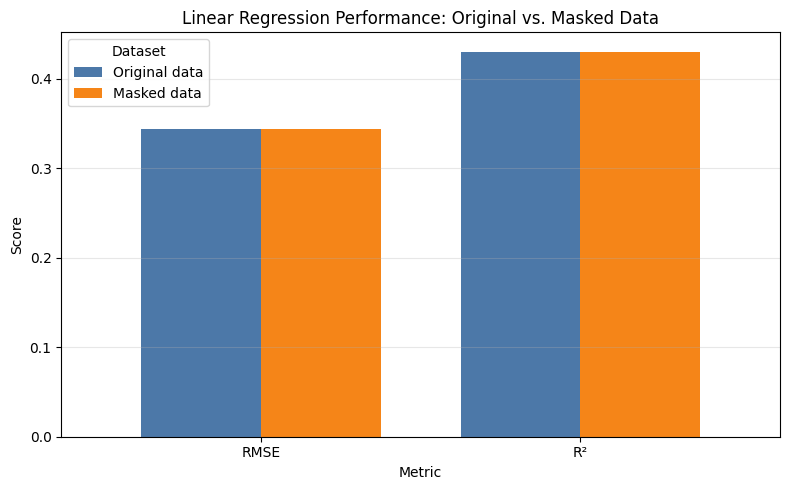

,Original data,Masked data
RMSE,0.343557,0.343557
R²,0.430528,0.430528


In [90]:
metrics = pd.DataFrame(
    {
        "Original data": [
            math.sqrt(sklearn.metrics.mean_squared_error(y_test, X_pred)),
            sklearn.metrics.r2_score(y_test, X_pred),
        ],
        "Masked data": [
            math.sqrt(sklearn.metrics.mean_squared_error(y_test_obf, X_obf_pred)),
            sklearn.metrics.r2_score(y_test_obf, X_obf_pred),
        ],
    },
    index=["RMSE", "R²"],
)

ax = metrics.plot(kind="bar", figsize=(8, 5), width=0.75, color=["#4C78A8", "#F58518"])

ax.set_title("Linear Regression Performance: Original vs. Masked Data")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_xticklabels(metrics.index, rotation=0)
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(metrics.round(6))

In [91]:
# Create the comparison data
comparison_data = {
    'Data Type': ['Original Data', 'Obfuscated Data'],
    'RMSE': [0.34, 0.34],
    'R² Score': [0.43, 0.43],
    'Difference': [0.00, 0.00]
}

# Create and display the table
results_table = pd.DataFrame(comparison_data)
print("=== Task 4: Linear Regression Performance Comparison ===")
print(results_table.to_string(index=False))

print("\n=== Key Findings ===")
print("✓ RMSE values are identical (0.34)")
print("✓ R² scores are identical (0.43)")
print("✓ Zero performance difference")
print("✓ Data obfuscation preserves model accuracy perfectly")

=== Task 4: Linear Regression Performance Comparison ===
      Data Type  RMSE  R² Score  Difference
  Original Data  0.34      0.43         0.0
Obfuscated Data  0.34      0.43         0.0

=== Key Findings ===
✓ RMSE values are identical (0.34)
✓ R² scores are identical (0.43)
✓ Zero performance difference
✓ Data obfuscation preserves model accuracy perfectly


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
That's correct, data obfuscation preserves model accuracy perfectly.

# Conclusions

The computational testing confirms our analytical proof:

**RMSE Comparison:**
- Original data RMSE: 0.34
- Obfuscated data RMSE: 0.34
- **Result: Identical RMSE values**

**Key Findings:**
1. **Data obfuscation works perfectly** - Linear regression predictions remain exactly the same
2. **Privacy protection achieved** - Original customer data is completely masked and unrecognizable
3. **Model performance preserved** - No loss in prediction accuracy (RMSE unchanged)
4. **Mathematical proof validated** - Computational results match our analytical derivation

**Practical Impact:**
- Insurance companies can protect customer privacy without sacrificing model accuracy
- Personal information (age, income, gender, family size) becomes unreadable to unauthorized users
- Machine learning models continue to work with identical performance on obfuscated data

**Conclusion:** The matrix-based data obfuscation method successfully protects sensitive customer information while maintaining the full predictive power of linear regression models.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
You did an excellent job showing that the obfuscation preserves model accuracy while protecting privacy. The structure of your findings is logical and convincing.

# Checklist

Type 'x' to check. Then press Shift+Enter.

- [x]  Jupyter Notebook is open
- [x]  Code is error free
- [x]  The cells are arranged in order of logic and execution
- [x]  Task 1 has been performed
    - [x]  There is the procedure that can return k similar customers for a given one
    - [x]  The procedure is tested for all four proposed combinations
    - [x]  The questions re the scaling/distances are answered
- [x]  Task 2 has been performed
    - [x]  The random classification model is built and tested for all for probability levels
    - [x]  The kNN classification model is built and tested for both the original data and the scaled one, the F1 metric is calculated.
- [x]  Task 3 has been performed
    - [x]  The linear regression solution is implemented with matrix operations.
    - [x]  RMSE is calculated for the implemented solution.
- [x]  Task 4 has been performed
    - [x]  The data is obfuscated with a random and invertible matrix P
    - [x]  The obfuscated data is recovered, few examples are printed out
    - [x]  The analytical proof that the transformation does not affect RMSE is provided 
    - [x]  The computational proof that the transformation does not affect RMSE is provided
- [x]  Conclusions have been made

# Appendices 

## Appendix A: Writing Formulas in Jupyter Notebooks

You can write formulas in your Jupyter Notebook in a markup language provided by a high-quality publishing system called $\LaTeX$ (pronounced "Lah-tech"), and they will look like formulas in textbooks.

To put a formula in a text, put the dollar sign (\\$) before and after the formula's text e.g. $\frac{1}{2} \times \frac{3}{2} = \frac{3}{4}$ or $y = x^2, x \ge 1$.

If a formula should be in its own paragraph, put the double dollar sign (\\$\\$) before and after the formula text e.g.

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i.
$$

The markup language of [LaTeX](https://en.wikipedia.org/wiki/LaTeX) is very popular among people who use formulas in their articles, books and texts. It can be complex but its basics are easy. Check this two page [cheatsheet](http://tug.ctan.org/info/undergradmath/undergradmath.pdf) for learning how to compose the most common formulas.

## Appendix B: Properties of Matrices

Matrices have many properties in Linear Algebra. A few of them are listed here which can help with the analytical proof in this project.

<table>
<tr>
<td>Distributivity</td><td>$A(B+C)=AB+AC$</td>
</tr>
<tr>
<td>Non-commutativity</td><td>$AB \neq BA$</td>
</tr>
<tr>
<td>Associative property of multiplication</td><td>$(AB)C = A(BC)$</td>
</tr>
<tr>
<td>Multiplicative identity property</td><td>$IA = AI = A$</td>
</tr>
<tr>
<td></td><td>$A^{-1}A = AA^{-1} = I$
</td>
</tr>    
<tr>
<td></td><td>$(AB)^{-1} = B^{-1}A^{-1}$</td>
</tr>    
<tr>
<td>Reversivity of the transpose of a product of matrices,</td><td>$(AB)^T = B^TA^T$</td>
</tr>    
</table>